# Deep Network Development, 2026 Autumn - Week 7 Practice - **Notebook for video recording**

## Loading data and converting it into a NumPy array

**Database:** We will continue working with the dataset introduced last week, the Titanic Dataset - https://www.kaggle.com/datasets/yasserh/titanic-dataset .

In [ ]:

titanic_csv_url = 'https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/dndmsc_public_files/titanic.csv'


### Dataset CSV file loading - Option 2: Using the built-in `csv` module of Python

**We will first download the dataset file** and then open it as a local file. In certain environments (e.g., Google Colab) bash commands can be executed from Jupyter notebook cells.

In [ ]:

# You need to do this when using Google Colab: download file to Colab disk by using the bash command 'wget'
#!wget https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/dndmsc_public_files/titanic.csv



--2026-10-18 01:31:43--  https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/dndmsc_public_files/titanic.csv
Resolving nipg12.inf.elte.hu (nipg12.inf.elte.hu)... 157.181.160.172
Connecting to nipg12.inf.elte.hu (nipg12.inf.elte.hu)|157.181.160.172|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 61194 (60K) [text/csv]
Saving to: ‘titanic.csv’

titanic.csv         100%[===================>]  59.76K   204KB/s    in 0.3s    

2026-10-18 01:31:45 (204 KB/s) - ‘titanic.csv’ saved [61194/61194]



**Opening the file**, converting it to a nested list of strings using the built-in Python `csv` module and then, **converting this into a nested list of numeric values.**

In [ ]:
import csv

with open('titanic.csv', 'r') as file:
    my_reader = csv.reader(file, delimiter=',')
    attr_names = next(my_reader)
    print(attr_names)

    sex_dict = {'female': 0, 'male': 1}
    embarked_dict = {'C': 0, 'Q': 1, 'S': 2}

    dataset = []
    for row in my_reader:
        dataset_row = []
        for item_idx, item in enumerate(row):
            item = item.strip()
            if item_idx in {1, 2, 5, 6, 7, 9}:
                val = float('nan') if item == '' else float(item)
            elif item_idx == 4:
                val = sex_dict[item]
            elif item_idx == 11:
                val = float('nan') if item == '' else embarked_dict[item]
            else:
                continue
            dataset_row.append(val)
        dataset.append(dataset_row)


['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


**Converting the nested list into a 2D NumPy array** and then **separating** the column of binary classification **labels** (survival information) into the `labels` 1D array **and** placing all remaining columns into the `inputs` 2D array which will be used as **input information** to our neural network.

In [ ]:

import numpy as np

dataset_arr = np.array(dataset, dtype=np.float32)
print(dataset_arr[:5])
print(dataset_arr.shape)

inputs = dataset_arr[:,1:]
print(f"inputs array shape: {inputs.shape}, dtype: {inputs.dtype}")
print(inputs[:5, :])
labels = dataset_arr[:,0].astype(np.int32)
print(f"labels array shape: {labels.shape}, dtype: {labels.dtype}")
print(labels[:5])

[[ 0.      3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 1.      3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      1.      0.     35.      1.      0.     53.1     2.    ]
 [ 0.      3.      1.     35.      0.      0.      8.05    2.    ]]
(891, 8)
inputs array shape: (891, 7), dtype: float32
[[ 3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      0.     35.      1.      0.     53.1     2.    ]
 [ 3.      1.     35.      0.      0.      8.05    2.    ]]
labels array shape: (891,), dtype: int32
[0 1 1 1 0]


### Dataset CSV file loading - Option 3: The Pandas package

Before continuing to process the dataset, we will consider a third alternative for loading the dataset: the **Pandas package.**

In [ ]:
import pandas as pd
titanic_dataframe = pd.read_csv(titanic_csv_url)
titanic_dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


With the `DataFrame.head()` function we can explore the first few rows of the dataset.

In [ ]:
titanic_dataframe.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


The columns of the dataset can be referred to in a dictionary-style when using DataFrames. Various functionalities from NumPy are available in Pandas too.

In [ ]:

print("pd unique Sex: ", pd.unique(titanic_dataframe["Sex"]))
print("pd unique Embarked: ", pd.unique(titanic_dataframe["Embarked"]))


pd unique Sex:  ['male' 'female']
pd unique Embarked:  ['S' 'C' 'Q' nan]


As Pandas is not part of the course at the moment, we will **extract the columns which are useful to us and convert them to NumPy numeric data type arrays** in appropriate ways.

In [ ]:

inputs1 = titanic_dataframe[["Pclass", "Age", "SibSp", "Parch", "Fare"]].to_numpy(dtype=np.float32)
inputs_sex = titanic_dataframe["Sex"].astype("category").cat.codes.to_numpy(dtype=np.float32)
inputs_emb = titanic_dataframe["Embarked"].astype("category").cat.codes.to_numpy(dtype=np.float32)
inputs_emb[inputs_emb == -1] = np.nan    # pandas converts NaNs into '-1' categorical label, now we set them back to NaN

print("np unique Sex: ", np.unique(inputs_sex))
print("np unique Embarked: ", np.unique(inputs_emb))


np unique Sex:  [0. 1.]
np unique Embarked:  [ 0.  1.  2. nan]


We apply NumPy reshaping, indexing and concatenation operations to achieve the exact format of the previous dataset loading approach.

In [ ]:

print(f"inputs1 array shape: {inputs1.shape}, dtype: {inputs1.dtype}")
print(f"inputs_sex array shape: {inputs_sex.shape}, dtype: {inputs_sex.dtype}")
print(f"inputs3 array shape: {inputs_emb.shape}, dtype: {inputs_emb.dtype}")

# To mimic column order of previous dataset loading approaches
inputs = np.concatenate([inputs1[:,0,None], inputs_sex[:,None], inputs1[:,1:], inputs_emb[:,None]], axis=1)
print(f"\ninputs array shape: {inputs.shape}, dtype: {inputs.dtype}")

# Note:
#    inputs1[:, 0]  -> (n_passengers,)
#    inputs1[:, [0]]  -> (n_passengers, 1)   advanced indexing - copy
#    inputs1[:, 0, None]  -> (n_passengers, 1)   basic indexing - view (more efficient)

print(f"\ninputs array shape: {inputs.shape}, dtype: {inputs.dtype}")
print(inputs[:5, :])


inputs1 array shape: (891, 5), dtype: float32
inputs_sex array shape: (891,), dtype: float32
inputs3 array shape: (891,), dtype: float32

inputs array shape: (891, 7), dtype: float32

inputs array shape: (891, 7), dtype: float32
[[ 3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      0.     35.      1.      0.     53.1     2.    ]
 [ 3.      1.     35.      0.      0.      8.05    2.    ]]


Finally, **the "Survived" label column can be converted to an 1D NumPy array**, too.

In [ ]:

labels = titanic_dataframe["Survived"].to_numpy(dtype=np.int32)
print(f"labels array shape: {labels.shape}, dtype: {labels.dtype}")
print(labels[:5])


labels array shape: (891,), dtype: int32
[0 1 1 1 0]


## The (very basic) pre-processing of the data for learning

**We need to perform certain pre-processing steps.** This week, we will do as little as possible. Next week, we will expand this part.

First, **we replace missing values** (represented by NaN values in the dataset) by zeros.

In [ ]:

print("How many NaNs are in the `inputs` array?", np.count_nonzero(np.isnan(inputs)))
print("How many NaNs are in the `labels` array?", np.count_nonzero(np.isnan(labels)))

inputs[np.isnan(inputs)] = 0.                 # An alternative specifically for NaN values: inputs = np.nan_to_num(inputs, nan=0.)

print("\nHow many NaNs are in the `inputs` array now?", np.count_nonzero(np.isnan(inputs)))


How many NaNs are in the `inputs` array? 179
How many NaNs are in the `labels` array? 0

How many NaNs are in the `inputs` array now? 0


**We split up the dataset to three strictly disjoint parts:** the training set, the validation set and the test set. Now, we will use split ratios of 60% / 20% / 20%.

In [ ]:
# dataset split through basic indexing
#    alternative: scikit-learn - sklearn.model_selection.train_test_split()

TRAINING_SET_RATIO = 0.6
VALIDATION_SET_RATIO = 0.2
assert TRAINING_SET_RATIO + VALIDATION_SET_RATIO < 1

n_training_samples = int(inputs.shape[0] * TRAINING_SET_RATIO)
n_validation_samples = int(inputs.shape[0] * VALIDATION_SET_RATIO)
validation_offset = n_training_samples
test_offset = n_training_samples + n_validation_samples

inputs_train = inputs[:validation_offset, :]
labels_train = labels[:validation_offset]
inputs_val = inputs[validation_offset:test_offset, :]
labels_val = labels[validation_offset:test_offset]
inputs_test = inputs[test_offset:, :]
labels_test = labels[test_offset:]

print(f"Training inputs shape: {inputs_train.shape}, labels shape: {labels_train.shape}")
print(f"Validation inputs shape: {inputs_val.shape}, labels shape: {labels_val.shape}")
print(f"Test inputs shape: {inputs_test.shape}, labels shape: {labels_test.shape}")


Training inputs shape: (534, 7), labels shape: (534,)
Validation inputs shape: (178, 7), labels shape: (178,)
Test inputs shape: (179, 7), labels shape: (179,)


<font color='red'>**Please note:** We have intentionally left out some important pre-processing steps this week, as our focus is on neural network training now. For instance, we did not ensure that the order of the passengers in the dataset was random. Consequently, we cannot be sure that the distribution of passengers from the two categories (died / survived) is similar in all three dataset splits. Such issues can result in total failure when machine learning methods are applied. We will discuss these essential pre-processing steps in more detail next week.</font>

## Converting the dataset arrays to tensors

In [ ]:

import torch


As we will use PyTorch to train neural networks, we need to convert the `inputs` and `labels` arrays to `torch.Tensor` type objects.

In [ ]:

inputs_train_t = torch.tensor(inputs_train, dtype=torch.float32)     # Input data types should be torch.float32
inputs_val_t = torch.tensor(inputs_val, dtype=torch.float32)
inputs_test_t = torch.tensor(inputs_test, dtype=torch.float32)
labels_train_t = torch.tensor(labels_train, dtype=torch.float32)     # For binary classification, the labels are "true probabilities": either 0 or 1. Data type should be torch.float32.
labels_val_t = torch.tensor(labels_val, dtype=torch.float32)
labels_test_t = torch.tensor(labels_test, dtype=torch.float32)

print(inputs_train_t.shape)
print(inputs_train_t[:5, :])
print(labels_train_t.shape)
print(labels_train_t[:5])


torch.Size([534, 7])
tensor([[ 3.0000,  1.0000, 22.0000,  1.0000,  0.0000,  7.2500,  2.0000],
        [ 1.0000,  0.0000, 38.0000,  1.0000,  0.0000, 71.2833,  0.0000],
        [ 3.0000,  0.0000, 26.0000,  0.0000,  0.0000,  7.9250,  2.0000],
        [ 1.0000,  0.0000, 35.0000,  1.0000,  0.0000, 53.1000,  2.0000],
        [ 3.0000,  1.0000, 35.0000,  0.0000,  0.0000,  8.0500,  2.0000]])
torch.Size([534])
tensor([0., 1., 1., 1., 0.])


## Defining a simple MLP neural network for the binary classification task

The `torch.nn` module contains high-level building blocks that helps us implement and use neural networks.

In [ ]:

import torch.nn as nn
import matplotlib.pyplot as plt        # needed for loss curve plotting later


To define a custom neural network architecture, we need to create a subclass for the `torch.nn.Module` class.
The main components of the `torch.nn.Module` class which we need to overload in our subclass:
- **The `__init__()` method:** We need to specify the components of our neural network here, especially those which have parameters to train (e.g., layers).
- **The `forward()` method:** This is the actual implementation of the hypothesis function. The method describes the steps needed to evaluate the network using the inputs to get the label predictions.

Below, we define a 3-layer Multi-layer Perceptron (MLP) neural network.

In [ ]:

class BinClassifierMLP(nn.Module):

  def __init__(self, n_input_vars):
        super().__init__()
        self.linear1 = nn.Linear(n_input_vars, 30)
        self.linear2 = nn.Linear(30, 20)
        self.linear3 = nn.Linear(20, 1)            # Binary classification: A single neuron in the last layer

  def forward(self, x):
      # print(x.shape)                  # (batch_size, n_input_vars)
      h = self.linear1(x)
      # print(h.shape)                  # (batch_size, 30)
      h = nn.functional.relu(h)
      h = self.linear2(h)
      h = nn.functional.relu(h)
      h = self.linear3(h)
      h = nn.functional.sigmoid(h)      # Binary classification: Sigmoid at the end
      return h


The same definition using the `torch.nn.Sequential` class as a list-like container for the layers.

In [ ]:

class BinClassifierMLP(nn.Module):

  def __init__(self, n_input_vars):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_input_vars, 30),
            nn.ReLU(),
            nn.Linear(30, 20),
            nn.ReLU(),
            nn.Linear(20, 1),           # Binary classification: A single neuron in the last layer
            nn.Sigmoid()                # Binary classification: Sigmoid at the end
        )

  def forward(self, x):
    return self.layers(x)


An alternative model for binary classification: A single neuron with a sigmoid (a logistic regression).

In [ ]:

class LogisticRegressionModel(nn.Module):

  def __init__(self, n_input_vars):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_input_vars, 1),        # Binary classification: A single neuron in the last (and only) layer
            nn.Sigmoid()                       # Binary classification: Sigmoid at the end
        )

  def forward(self, x):
      return self.layers(x)


**Instantiating** our neural network (or logistic regression) model.

In [ ]:
MODEL_TO_USE = 'mlp'
assert MODEL_TO_USE in ['logreg', 'mlp']

if MODEL_TO_USE == 'logreg':
    bincl_model = LogisticRegressionModel(n_input_vars=inputs_train.shape[1])
elif MODEL_TO_USE == 'mlp':
    bincl_model = BinClassifierMLP(n_input_vars=inputs_train.shape[1])


## Training the neural network

Besides the standard Binary Cross-entropy (BCE) loss, we would like to measure the performance of the model using the **binary accuracy metric** too. This metric is easier to interpret for a human: the ratio of correctly classified examples.

We now define this metric manually.

In [ ]:

@torch.no_grad()
def bin_acc_fn(y_hat, y_true):                                 # An accuracy metric only suitable for binary classification
    # y_hat: (batch_size, 1) single probability, y_true: (batch_size, 1) float32 in {0,1}
    assert y_hat.shape == y_true.shape
    return torch.count_nonzero(torch.round(y_hat) == y_true) / y_hat.shape[0]


### Training - Option 1: Minibatch iteration implemented with a simple loop

We implement the mini-batch iteration with a simple loop and tensor slicing. We will run the training for a total of 50 epochs. In each epoch, we go through the training set once by mini-batch iteration, then evaluate the performance of the model on the validation set too. No early stopping is used yet. Following the training procedure, we evaluate the performance of the trained model on the test set. Finally, we plot the training and validation curves for the BCE loss and binary accuracy metric values measured in each epoch.

/tmp/ipykernel_1580/263472326.py:36: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  train_losses_in_epoch = torch.tensor(train_losses_in_epoch)


Epoch #0, tr loss: 0.7151387333869934, val loss: 0.6266079545021057, tr acc: 0.5182152390480042, val acc: 0.6464120745658875
Epoch #1, tr loss: 0.6463494896888733, val loss: 0.6134628057479858, tr acc: 0.6328542828559875, val acc: 0.7152778506278992
Epoch #2, tr loss: 0.6432658433914185, val loss: 0.6117715835571289, tr acc: 0.6467245817184448, val acc: 0.725694477558136
Epoch #3, tr loss: 0.6404008269309998, val loss: 0.6095297932624817, tr acc: 0.6522393226623535, val acc: 0.7048611640930176
Epoch #4, tr loss: 0.6370882987976074, val loss: 0.6056542992591858, tr acc: 0.6595922112464905, val acc: 0.7048611640930176
Epoch #5, tr loss: 0.6341605186462402, val loss: 0.6028884649276733, tr acc: 0.6651069521903992, val acc: 0.7152778506278992
Epoch #6, tr loss: 0.6315196752548218, val loss: 0.6008217930793762, tr acc: 0.6651069521903992, val acc: 0.7048611640930176
Epoch #7, tr loss: 0.6294856071472168, val loss: 0.5985789895057678, tr acc: 0.6632686853408813, val acc: 0.7048611640930176
E

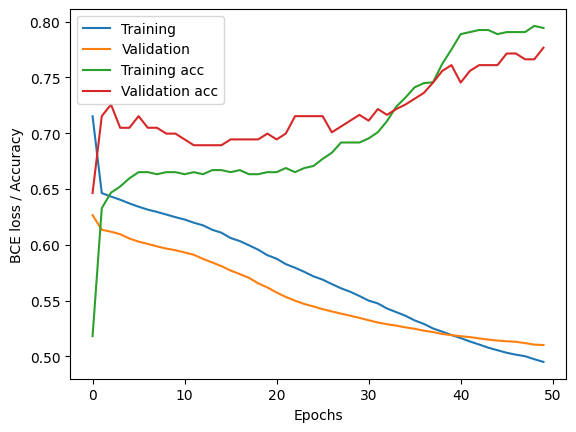

In [ ]:
loss_fn = nn.BCELoss()

n_epochs = 50                           # Now, we will iterate for a fixed number of epochs. We will add early stopping later...
learning_rate = 0.001
batch_size = 32
optimizer = torch.optim.Adam(bincl_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []

for epoch_idx in range(n_epochs):

    # training
    bincl_model.train()                  # just setting a flag (setting our neural network model in a training mode)
    train_losses_in_epoch = []
    train_accs_in_epoch = []

    for offset_idx in range(0, inputs_train_t.shape[0], batch_size):
        end_offset_idx = min(offset_idx + batch_size, inputs_train_t.shape[0])
        train_batch_xs = inputs_train_t[offset_idx:end_offset_idx, :]        # (batch_size OR smaller_last_batch_size, n_input_vars)
        train_batch_ys = labels_train_t[offset_idx:end_offset_idx, None]     # (batch_size OR smaller_last_batch_size, 1)

        optimizer.zero_grad()
        train_batch_ys_pred = bincl_model(train_batch_xs)        # (batch_size OR smaller_last_batch_size, n_input_vars) -> (batch_size OR smaller_last_batch_size, 1)
        loss = loss_fn(train_batch_ys_pred, train_batch_ys)      # 'loss' always has to be a scalar
        acc = bin_acc_fn(train_batch_ys_pred, train_batch_ys)    # scalar

        train_losses_in_epoch.append(loss)
        train_accs_in_epoch.append(acc)

        loss.backward()
        optimizer.step()

    train_losses_in_epoch = torch.tensor(train_losses_in_epoch)
    train_accs_in_epoch = torch.tensor(train_accs_in_epoch)
    avg_tr_epoch_loss = train_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_tr_epoch_acc = train_accs_in_epoch.mean()
    train_losses.append(avg_tr_epoch_loss)
    train_accuracy.append(avg_tr_epoch_acc)

    # validation
    bincl_model.eval()                  # just setting a flag (setting our neural network model in a non-training mode)
    val_losses_in_epoch = []
    val_accs_in_epoch = []

    for offset_idx in range(0, labels_val_t.shape[0], batch_size):
        end_offset_idx = min(offset_idx + batch_size, labels_val_t.shape[0])
        val_batch_xs = inputs_val_t[offset_idx:end_offset_idx, :]
        val_batch_ys = labels_val_t[offset_idx:end_offset_idx, None]

        with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
            val_batch_ys_pred = bincl_model(val_batch_xs)
        loss = loss_fn(val_batch_ys_pred, val_batch_ys)
        acc = bin_acc_fn(val_batch_ys_pred, val_batch_ys)

        val_losses_in_epoch.append(loss)
        val_accs_in_epoch.append(acc)

    val_losses_in_epoch = torch.tensor(val_losses_in_epoch)
    val_accs_in_epoch = torch.tensor(val_accs_in_epoch)
    avg_val_epoch_loss = val_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_val_epoch_acc = val_accs_in_epoch.mean()
    val_losses.append(avg_val_epoch_loss)
    val_accuracy.append(avg_val_epoch_acc)

    # logging
    print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")

    # (end of training loop)

print("Training finished.")

# training has finished; evaluate trained model on test set (measure loss, accuracy on test set)
test_ys_preds = []
for offset_idx in range(0, labels_test_t.shape[0], batch_size):               # if the whole test set evaluation fits into memory, no need to do batches here, can be done in one go
    end_offset_idx = min(offset_idx + batch_size, labels_test_t.shape[0])
    test_batch_xs = inputs_test_t[offset_idx:end_offset_idx, :]
    test_batch_ys = labels_test_t[offset_idx:end_offset_idx, None]

    with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
        test_batch_ys_pred = bincl_model(test_batch_xs)
        test_ys_preds.append(test_batch_ys_pred)

test_ys_preds = torch.cat(test_ys_preds, axis=0)
test_loss = loss_fn(test_ys_preds, labels_test_t[:,None])
test_acc = bin_acc_fn(test_ys_preds, labels_test_t[:,None])

print(f"Test loss: {test_loss}, test acc: {test_acc}")

# Plot training/val curves
plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss / Accuracy')
plt.legend()
plt.show()


We reach a binary accuracy of around 80% on the test set. **The results are hard to interpret as we haven't accounted for the non-uniform distribution of categories** (the different number of passengers surviving and dying).

We will improve our procedure next week.